**Welcome everyone!** 


- **Extra Readings:**\
SBGP: Shmueli, Bruce, Gedeck, Patel, Data Mining for Business Analytics: Concepts, Techniques, and Applications in Python; \
[Extra:] Turrell's Coding for Economists. Online resource: https://aeturrell.github.io/coding-for-economists/intro.html \


As you opened this ypynb file, you already have got a py interpreter. \
Among the many, I recommend Microsoft’s Visual Studio (**VS**) Code.\
Why? On top of being free and open source IDE (Integrated Development Environment),
- provides a way to **debug** (look for errors) in your code & automatic code checking for basic errors;
- provides auto-completion of your code when you hit TAB;
- tracks the **colouring** (so you can keep track of the logical order);
- most importantly: **powered by AI**. *But this will be explored later in the course*

For further readings, check: https://aeturrell.github.io/coding-for-economists/code-preliminaries.html

In [41]:
#%pip install rich numpy pandas scikit-learn dmba statsmodels matplotlib seaborn
%matplotlib inline

In [42]:
## Basic coding

## define a list of  prime numbers
primes = [2, 3, 5, 7, 11, 13, 17]
print(type(primes))
## generate a list of numbers that are twice the primes
twice = [el * 2 for el in primes] 
## uncomment the next lines for tracking what you created
#primes
#twice

## slicing
print(primes[0]) # print the first prime (python starts at 0)
print(primes[-1]) # print the last prime
print(primes[-5:-1]) # print the last prime

## strings
string = "list_of_PRIMES"
print(string[-6:]) # print the last 6 letters of the string: "PRIMES
string = string.replace("_", " ").rstrip().lower()
print(string)

## finding whether the number is divisible by any of the previous ones
## for, if and booleans
for i in range(len(primes)):
    num = primes[i]  # the number which is analyzed
    smaller = primes[:i]  # all previous numbers in the list
    not_divisible_by = [] # we will store here the numbers that do not divide num
    
    for s in smaller: 
        if num % s != 0: # modulo operator: the remainder when num is divided by s.
            not_divisible_by.append(str(s))
    
    if not_divisible_by:
        print(f"the number {num} is not divisible by {' '.join(not_divisible_by)}")

## built-in functions
sum(primes)
## how to learn about functions? 
help(sum) # to understand what the function does
from rich import inspect
inspect(sum, help=True)


<class 'list'>
2
17
[5, 7, 11, 13]
PRIMES
list of primes
the number 3 is not divisible by 2
the number 5 is not divisible by 2 3
the number 7 is not divisible by 2 3 5
the number 11 is not divisible by 2 3 5 7
the number 13 is not divisible by 2 3 5 7 11
the number 17 is not divisible by 2 3 5 7 11 13
Help on built-in function sum in module builtins:

sum(iterable, /, start=0)
    Return the sum of a 'start' value (default: 0) plus an iterable of numbers
    
    When the iterable is empty, return the start value.
    This function is intended specifically for use with numeric values and may
    reject non-numeric types.



╭───────────────────────── <built-in function sum> ──────────────────────────╮
│ def sum(iterable, /, start=0):                                             │
│                                                                            │
│ Return the sum of a 'start' value (default: 0) plus an iterable of numbers │
│                                                                            │
│ When the iterable is empty, return the start value.                        │
│ This function is intended specifically for use with numeric values and may │
│ reject non-numeric types.                                                  │
│                                                                            │
│ 30 attribute(s) not shown. Run inspect(inspect) for options.               │
╰────────────────────────────────────────────────────────────────────────────╯

Let's start our journey with a classic example: **WestRoxbury's dataset**. \
The data is about house prices in Massachusetts (Boston and West Roxbury).\
But first, let us **import** the relevant packages.

In [43]:
## import packages
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


import matplotlib.pyplot as plt
import seaborn as sns

## uncomment the next line if you haven't installed dmba yet
# %pip install dmba
from dmba import regressionSummary               

After importing the packages, we can start dirtying our hands with data work.\
We will be importing the dataset from csv (*pd.read_csv*), and **visualizing** it: fully and by rows/columns.

In [44]:
## load data
housing_df = pd.read_csv('../0_datasets/WestRoxbury.csv') # '../' means go up one directory

## visualizing data
## usually: rows x columns are observations x variables
housing_df.shape  # dimensions
housing_df.head()  # first five rows

## visualizing rows via .loc[...]
housing_df.loc[0:2]  # loc[a:b] gives rows 0 to 3, inclusive
housing_df.iloc[0:3]  # iloc[a:b] gives rows 0 to 4-1=3, excluding the last index

## visualizing columns via nameofdataset['...']
housing_df.columns  # column names
housing_df.dtypes  # data types of each column
housing_df['TAX']  # column named 'TAX'
housing_df[['TAX', 'YR BUILT']]  # columns named 'TAX' and 'PRICE'
housing_df[['TAX', 'YR BUILT']].tail(10)  # last 10 values 

## visualizing all data
print(housing_df)  # show all the data
## watch out: if the dataset is large, this will flood your screen      

## visualizing slices: I want to see the eighth row of the fifth to the eleventh row
## via .loc[startrow:stoprow:step, startcolumn:stopcolumn:step] 
## or .iloc[start:stop:step, start:stop:step]
housing_df.iloc[8, 4:11] # single-step indexing
housing_df.iloc[8:9, 4:11] # use a slice 
## to use negative indexing: uncomment the next line
#housing_df.iloc[8,-10:-3] # use negative indexing

## for a better visualization: uncomment the next lines
#from skimpy import skim
#skim(housing_df)


      TOTAL VALUE    TAX  LOT SQFT   YR BUILT  GROSS AREA   LIVING AREA  \
0            344.2  4330       9965      1880         2436         1352   
1            412.6  5190       6590      1945         3108         1976   
2            330.1  4152       7500      1890         2294         1371   
3            498.6  6272      13773      1957         5032         2608   
4            331.5  4170       5000      1910         2370         1438   
...            ...   ...        ...       ...          ...          ...   
5797         404.8  5092       6762      1938         2594         1714   
5798         407.9  5131       9408      1950         2414         1333   
5799         406.5  5113       7198      1987         2480         1674   
5800         308.7  3883       6890      1946         2000         1000   
5801         447.6  5630       7406      1950         2510         1600   

      FLOORS   ROOMS  BEDROOMS   FULL BATH  HALF BATH  KITCHEN  FIREPLACE  \
0         2.0      6  

,GROSS AREA,LIVING AREA,FLOORS,ROOMS,BEDROOMS,FULL BATH,HALF BATH
8,2582,1092,1.0,5,3,1,0


When dealing with row data, some **relabelling** is needed.\
Plus, here below, some examples about how to access and visualize specific rows/columns/entries.

In [45]:
## relabelling

## remove spaces in column names
housing_df = housing_df.rename(columns={'TOTAL VALUE ': 'TOTAL_VALUE'}) # explicit example
housing_df.columns = [s.strip().replace(' ', '_') for s in housing_df.columns] # all at once
## note that we did not create a new set of columns.
## if needed to create new columns:uncomment the next lines.
#housing_df['LOT_SQFT_k'] = housing_df['LOT_SQFT']/1000.
#housing_df.assign(LOT_SQFT_k=housing_df["LOT_SQFT"] / 1000)
## quick check: uncomment the next line
#print(housing_df) 

housing_df.iloc[0:1,:] # full first row
housing_df['TOTAL_VALUE'][0:10] # first 10 rows of the first column
housing_df.iloc[0:10].TOTAL_VALUE # note: 'TOTAL VALUE ' -->'TOTAL_VALUE'
housing_df.iloc[:,0:1] # full first column
housing_df.TOTAL_VALUE # idem
## to filter rows based on a condition: uncomment the next line
#housing_df.query("TOTAL_VALUE>1000") # there should be two obs.

## ranking by some specific variables: uncomment the next lines
#housing_df.sort_values(["TOTAL_VALUE", "YR BUILT"])

0       344.2
1       412.6
2       330.1
3       498.6
4       331.5
        ...  
5797    404.8
5798    407.9
5799    406.5
5800    308.7
5801    447.6
Name: TOTAL_VALUE, Length: 5802, dtype: float64

Good practice is to **duplicate/create** (if needed) new datasets from the original one, so to keep track of the modifications that have been done.

In [46]:
## creating new dataframes 

## suppose we want a new dataframe with rows 4-5 and columns 0-1 and 4-5
housing_df.iloc[4:6,0:2]
housing_df.iloc[4:6,4:6]
housing_tiny_df = pd.concat([housing_df.iloc[4:6,0:2], housing_df.iloc[4:6,4:6]], axis=1)
## quick check: uncomment the next line
#print(housing_tiny_df)

## copy dataset
housing_df_copy = housing_df.copy()
print(housing_df_copy) 


      TOTAL_VALUE   TAX  LOT_SQFT  YR_BUILT  GROSS_AREA  LIVING_AREA  FLOORS  \
0           344.2  4330      9965      1880        2436         1352     2.0   
1           412.6  5190      6590      1945        3108         1976     2.0   
2           330.1  4152      7500      1890        2294         1371     2.0   
3           498.6  6272     13773      1957        5032         2608     1.0   
4           331.5  4170      5000      1910        2370         1438     2.0   
...           ...   ...       ...       ...         ...          ...     ...   
5797        404.8  5092      6762      1938        2594         1714     2.0   
5798        407.9  5131      9408      1950        2414         1333     2.0   
5799        406.5  5113      7198      1987        2480         1674     2.0   
5800        308.7  3883      6890      1946        2000         1000     1.0   
5801        447.6  5630      7406      1950        2510         1600     2.0   

      ROOMS  BEDROOMS  FULL_BATH  HALF_

Let us now dive into the **descriptive statistics**.\
Generally, we may need to look at measures of center (e.g., mean, median), dispersion (std,25%,75%), range (e.g., count, min, max) to statistically have an idea on which sample and what kind of variables we are dealing with. 

In [47]:
## descriptive:

print('# of obs.:', len(housing_df['TOTAL_VALUE'])) # length: number of obs.
print('mean of TOTAL_VALUE:', housing_df['TOTAL_VALUE'].mean()) # mean of column
housing_df.describe() # show stats for each column: count, mean, std, min, 25%, 50%, 75%, max

# descriptive stats by groups: uncomment the next line
#housing_df.groupby("ROOMS").mean(numeric_only=True)
#print(housing_df.groupby(["ROOMS", "FLOORS"]).agg(
#    avg_tax=("TAX", "mean"),
#    avg_TV=("TOTAL_VALUE", "mean"),
#    std_living=("LIVING_AREA", "std"),
#    ))

## describe() is only numeric (float/int): non-numeric (e.g., REMODEL) are ignored
housing_df.dtypes
## REMODEL: object --> categorical
housing_df.REMODEL = housing_df.REMODEL.astype('category') 
housing_df.REMODEL.dtype  # check type of REMODEL
## to see summary stats for all: uncomment the next line
#housing_df.describe(include='all')

## frequency table for REMODEL
housing_df.REMODEL.value_counts() # frequency table; for the relative: value_counts(normalize=True)

## notice that # of obs. is >> sum of frequencies due missing values/NAs
## quick check: uncomment the next line
#housing_df.REMODEL.isna().sum() # count the number of rows with NAs in REMODEL

## tabulate values
table = housing_df_copy[["TOTAL_VALUE", "TAX"]].agg(["mean", "std"])
print(table)
## uncomment to use latex
#print(table.style.to_latex(caption="A Table", label="tab:descriptive"))

## cross-tabulation of REMODEL vs ROOMS: uncomment the next line
#pd.crosstab(housing_df.REMODEL, housing_df.ROOMS) 


# of obs.: 5802
mean of TOTAL_VALUE: 392.6857149258877
      TOTAL_VALUE          TAX
mean   392.685715  4939.485867
std     99.177414  1247.649118


Unfortunately (and many times!), we need to deal with **missing values**.\
Here below, we first create missing values and then impute the medians.

In [48]:
## NAs (missing or unavailable) =/= NaN (Not a Number)
## synthetic example: convert entries of BEDROOMS to NA's by randomly select 50 rows (~1%)

## check starting point: uncomment the next 2 lines
#print('PRE. # of obs.: 5802 vs. # valid BEDROOMS values:',
#       housing_df_copy['BEDROOMS'].count())

missingrows = housing_df_copy.sample(50).index  # randomly select 50 rows
housing_df_copy.loc[missingrows, 'BEDROOMS'] = np.nan  # set those rows to NA
print('# of obs.:', housing_df['BEDROOMS'].count(),
      ' vs. # valid BEDROOMS values:', housing_df_copy['BEDROOMS'].count()) 

## remove rows with BEDROOM missing values  
reduced_df = housing_df_copy.dropna(subset=['BEDROOMS'])

## remove all rows with any missing values (including REMODEL)
reduced_df2 = housing_df_copy.dropna() # 
print('# valid BEDROOMS values:', reduced_df['TOTAL_VALUE'].count(), 
      'vs. # all valid values:', reduced_df2['TOTAL_VALUE'].count())  

## imputation: median of the remaining values.
medianbedrooms = housing_df_copy['BEDROOMS'].median()
housing_df_copy.BEDROOMS = housing_df_copy.BEDROOMS.fillna(value=medianbedrooms)
print('Post-imputation. # valid BEDROOMS values:', housing_df_copy['TOTAL_VALUE'].count(),
       'vs. # valid values of original:', housing_df['TOTAL_VALUE'].count())

## watch out: if you run it multiple times, you will keep replacing the NA's with the median.
## how you handle missing values can affect your analysis.
## check the mean and std of BEDROOMS before and after imputation
print('mean of BEDROOMS original:', round(housing_df['BEDROOMS'].mean(),5),
      'vs. mean of imputed:', round(housing_df_copy['BEDROOMS'].mean(),5))  
print('std of BEDROOMS original:', round(housing_df['BEDROOMS'].std(),5),
      'vs. std of imputed:', round(housing_df_copy['BEDROOMS'].std(),5))    


## creating new columns: uncomment the next lines
#housing_df_copy["VALUE_AFTERTAX"] = housing_df_copy["TOTAL_VALUE"] - housing_df_copy["TAX"]
#housing_df_copy.drop('VALUE_AFTERTAX', axis=1) 


# of obs.: 5802  vs. # valid BEDROOMS values: 5752
# valid BEDROOMS values: 5752 vs. # all valid values: 1441
Post-imputation. # valid BEDROOMS values: 5802 vs. # valid values of original: 5802
mean of BEDROOMS original: 3.23009 vs. mean of imputed: 3.22906
std of BEDROOMS original: 0.84661 vs. std of imputed: 0.84322


Once we have a complete dataset, we can think about the next steps.\
Some algorithms (or statistical models) would require some form of **normalization** of the data.\
Here below, we also consider an example about **creating dummies**. 

In [49]:
## normalizing a dataset 
housing_df_copy = housing_df.copy()  # make a copy

## separate numeric and categorical columns
numeric_cols = housing_df_copy.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = housing_df_copy.select_dtypes(exclude=["int64", "float64"]).columns
## equally: categorical_cols = housing_df_copy.select_dtypes(include=["object", "category"]).columns
## or, for REMODEL: categorical_cols = ["REMODEL"]

# Z-score normalization: (numeric_cols - numeric_cols.mean()) / numeric_cols.std()
scaler = StandardScaler()
norm_numeric = pd.DataFrame(
                            scaler.fit_transform(housing_df_copy[numeric_cols]),
                            index=housing_df_copy.index,
                            columns=numeric_cols
                            )

## rescaling a dataset: (numeric_cols - numeric_cols.min()) / (numeric_cols.max() - numeric_cols.min())
scaler2 = MinMaxScaler()
norm2_numeric = pd.DataFrame(
                            scaler2.fit_transform(housing_df_copy[numeric_cols]),
                            index=housing_df_copy.index,
                            columns=numeric_cols
                            )

## append categorical columns
norm_df = pd.concat([norm_numeric, housing_df_copy[categorical_cols]], axis=1)
norm2_df = pd.concat([norm2_numeric, housing_df_copy[categorical_cols]], axis=1)

## original dataset vs. standardized or scaled      
print('Normalization. TAX mean:', round(norm_df['TAX'].mean(),5), 'and std:', round(norm_df['TAX'].std(),5),
      'vs. original TAX mean:', round(housing_df_copy['TAX'].mean(),5), 'and std:', round(housing_df_copy['TAX'].std(),5))
print('Rescaling. TAX min:', norm2_df['TAX'].min(),' and max:', norm2_df['TAX'].max(),
        'vs. original TAX min:', housing_df_copy['TAX'].min(), 'and max:', housing_df_copy['TAX'].max()) 

## standardized vs. scaled datasets
print('standardized TAX 75p:', norm_df['TAX'].quantile(0.75), 'vs. scaled TAX 75p', norm2_df['TAX'].quantile(0.9))

## scale the categorical variables (e.g., REMODEL) via dummy variables (one-hot encoding)    
print('Categorical columns:', categorical_cols)   
dummy_vars = pd.get_dummies(housing_df_copy[categorical_cols], prefix=categorical_cols, dtype=float)

## to avoid multicollinearity, use drop_first=True
dummy_vars = pd.get_dummies(housing_df_copy[categorical_cols], prefix=categorical_cols, 
                            drop_first=True, dtype=float)
## the baseline will be REMODEL_Old

## to relabel the dummies via rename: uncomment the next lines
#dummy_vars = dummy_vars.rename(columns={
#    "REMODEL_Old": "REMODEL_OLD",
#    "REMODEL_Recent": "REMODEL_RECENT"
#                                         })

## example of function to rename the dummies
def rename_dummies(col_name):
    var, category = col_name.split("_", 1)
    return f"{var}={category}"
dummy_vars = dummy_vars.rename(columns=lambda x: rename_dummies(x)) # apply renaming

## append (categorical) columns
norm_df  = pd.concat([norm_numeric, dummy_vars], axis=1)   
norm2_df = pd.concat([norm2_numeric, dummy_vars], axis=1)  
norm_df.columns


Normalization. TAX mean: -0.0 and std: 1.00009 vs. original TAX mean: 4939.48587 and std: 1247.64912
Rescaling. TAX min: 0.0  and max: 1.0 vs. original TAX min: 1320 and max: 15319
standardized TAX 75p: 0.4649256871587789 vs. scaled TAX 75p 0.3753839559968569
Categorical columns: Index(['REMODEL'], dtype='str')


Index(['TOTAL_VALUE', 'TAX', 'LOT_SQFT', 'YR_BUILT', 'GROSS_AREA',
       'LIVING_AREA', 'FLOORS', 'ROOMS', 'BEDROOMS', 'FULL_BATH', 'HALF_BATH',
       'KITCHEN', 'FIREPLACE', 'REMODEL=Recent'],
      dtype='str')

If the analysis involves either out-of-sample prediction or tuning (regarding the algorithm to implement), we need to **split the data** into different sets.

In [50]:
## split data into training, validation, and test sets
## for linear regression, there is no need for three-way split.       
## training (60%) and validation (40%). Recall to set random_state for reproducibility
trainData, validData = train_test_split(housing_df, test_size=0.40, random_state=1) 
print('Training: ', trainData.shape)
print('Validation: ', validData.shape)
print()
## for other models, you may want to have the three-way split.
# training (50%), validation (30%), and test (20%). Recall to set random_state for reproducibility
trainData, temp = train_test_split(housing_df, test_size=0.5, random_state=1)
validData, testData = train_test_split(temp, test_size=0.4, random_state=1) # 40% of 50% = 20%
print('Training: ', trainData.shape)
print('Validation: ', validData.shape)
print('Test: ', testData.shape)

Training:  (3481, 14)
Validation:  (2321, 14)

Training:  (2901, 14)
Validation:  (1740, 14)
Test:  (1161, 14)


A brief example of **regression analysis** is presented here below. \
The objective is to predict the target (or dependent) variable: TOTAL_VALUE. The predictors (or explanatory variables) are all others except for: TAX. The statistical model (or algorithm) is the linear regression model (OLS).\
Here below, few ways to assess the forecasting ability of the model.

In [51]:
## preliminary regression analysis
## there is no need to standardize or scale the data for linear regression

## recall to have dropped the dummy variable to avoid multicollinearity
## avoid missing values
norm_df = norm_df.dropna()

## the task is to predict TOTAL_VALUE (or TAX) using the other variables
## create list of predictors/explanatory X and outcome/target y
excludetarget = ('TOTAL_VALUE', 'TAX')
predictors = [s for s in norm_df.columns if s not in excludetarget]
target = 'TOTAL_VALUE' # or 'TAX'
X = norm_df[predictors]
y = norm_df[target]

## partition data to evaluate the prediction performance
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4,random_state=14)
## linear regression
model = LinearRegression()
## in-sample fit
model.fit(train_X, train_y)   
train_pred = model.predict(train_X)  
train_results = pd.DataFrame({
    'TOTAL_VALUE': train_y,
    'predicted': train_pred,
    'residual': train_y - train_pred
})
print(train_results)
## out-of-sample prediction
valid_pred = model.predict(valid_X)
valid_results = pd.DataFrame({
    'TOTAL_VALUE': valid_y,
    'predicted': valid_pred,
    'residual': valid_y - valid_pred
})
valid_results.head()

## using the dmba package to summarize the regression results
## training set: uncomment the next line
regressionSummary(train_results.TOTAL_VALUE, train_results.predicted)
## validation set: uncomment the next line
regressionSummary(valid_results.TOTAL_VALUE, valid_results.predicted)

      TOTAL_VALUE  predicted  residual
1635    -0.539340   0.087874 -0.627214
2152     0.722145   0.812938 -0.090793
4932    -0.461694  -0.277994 -0.183700
1903    -1.308734  -1.512940  0.204206
4767     2.033040   1.482217  0.550823
...           ...        ...       ...
3833    -1.144368  -1.434143  0.289775
2454     0.090898   0.323886 -0.232987
1292     1.424986   1.024034  0.400952
5464     0.401480   0.322040  0.079440
2667     0.574921   0.332986  0.241935

[3481 rows x 3 columns]

Regression statistics

                      Mean Error (ME) : 0.0000
       Root Mean Squared Error (RMSE) : 0.4298
            Mean Absolute Error (MAE) : 0.3230
          Mean Percentage Error (MPE) : 48.4493
Mean Absolute Percentage Error (MAPE) : 176.1026

Regression statistics

                      Mean Error (ME) : -0.0074
       Root Mean Squared Error (RMSE) : 0.4538
            Mean Absolute Error (MAE) : 0.3342
          Mean Percentage Error (MPE) : -95.8543
Mean Absolute Percentage Error

In [52]:
## more detailed regression results via statsmodels

## to install statsmodels: uncomment the next line
#!pip install statsmodels
import statsmodels.api as sm
X_sm = sm.add_constant(X)  #add an intercept (beta_0) to our model
ols_model = sm.OLS(y, X_sm).fit() # in-sample fit

## print a more complete summary
print(ols_model.summary())

## sklearn: out-of-sample prediction and model evaluation.
## statsmodels: inference & diagnostics.

## note the comment: "Standard Errors assume that the covariance matrix of the errors is correctly specified."

## to have robust standard errors (e.g., HC3): uncomment the next lines
#ols_model_HC3 = sm.OLS(y, X_sm).fit(cov_type='HC3') # in-sample fit
#print(ols_model_HC3.summary())
## it should be the default! But you can also use others, and you can test them (e.g., White (1980)'s test).


                            OLS Regression Results                            
Dep. Variable:            TOTAL_VALUE   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     2038.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:13:54   Log-Likelihood:                -3436.7
No. Observations:                5802   AIC:                             6899.
Df Residuals:                    5789   BIC:                             6986.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -0.0375      0.006     -5.

The R squared is quite high.\
It is a metric that measures the performance of a model in explaining the target. It ranges between 0 and 1, and is defined as: $R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$

The linear regression model is doing a fairly good job in predicting the housing values.

*Is the job done?*

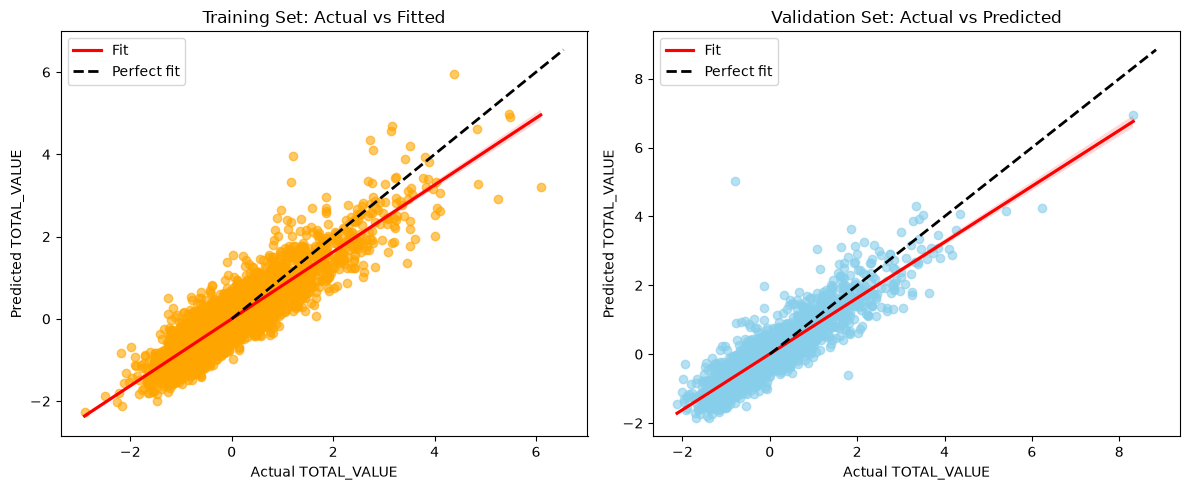

In [53]:
## visualizing the fit

## install matplotlib and seaborn
import matplotlib.pyplot as plt
import seaborn as sns

## set the figure size
plt.figure(figsize=(12,5)) 

## we want two plots side by side: in-sample and out-of-sample
## in-sample fit
plt.subplot(1,2,1)
sns.regplot(
    x=train_results['TOTAL_VALUE'], 
    y=train_results['predicted'], 
    scatter_kws={'alpha':0.6, 'color':'orange'}, 
    line_kws={'color':'red'}
)
ax = plt.gca()     
ax.get_lines()[0].set_label('Fit') # set label for the regression slope       
lims = [0, max(plt.xlim()[1], plt.ylim()[1])]  # get the larger of x and y axis limits
plt.plot(lims, lims, 'k--', lw=2, label='Perfect fit')  # 45-degree line (perfect predictions y=fitted_y)
plt.title("Training Set: Actual vs Fitted")
plt.xlabel("Actual TOTAL_VALUE")
plt.ylabel("Predicted TOTAL_VALUE")
plt.legend()

# out-of-sample fit
plt.subplot(1,2,2)
sns.regplot(
    x=valid_results['TOTAL_VALUE'], 
    y=valid_results['predicted'], 
    scatter_kws={'alpha':0.6, 'color':'skyblue'}, 
    line_kws={'color':'red'}
)
ax = plt.gca()     
ax.get_lines()[0].set_label('Fit') # set label for the regression slope  
lims = [0, max(plt.xlim()[1], plt.ylim()[1])]  # get the larger of x and y axis limits
plt.plot(lims, lims, 'k--', lw=2, label='Perfect fit')  # 45-degree line (perfect predictions y=fitted_y)
plt.title("Validation Set: Actual vs Predicted")
plt.xlabel("Actual TOTAL_VALUE")
plt.ylabel("Predicted TOTAL_VALUE")
plt.legend()

## show the plots
plt.tight_layout()
plt.show()


What can we see is that for large positive values, the model tends to underfit (i.e., producing predictions smaller than the actual values).

---
# Part A — From regression to data visualization

Let us pause and look back at the last figure of the regression analysis (*actual vs. predicted* values).

Two things are worth noticing:
- for the most expensive houses, the dots lie **below** the dashed 45-degree line: the model tends to predict values that are too low for them;
- the axes are in **standardized units (z-scores)**, not in dollars. This is because the regression used `norm_df`, where every numeric column (including TOTAL_VALUE) was standardized. A value of 0 means "an average house", a value of 2 means "two standard deviations above the average".

This raises a natural question: *what does the data look like before we fit any model?*\
**Data visualization** helps us answer three simple questions:
1. How are house values distributed? (Are there many very expensive houses?)
2. Which property characteristics move together with the value?
3. Which characteristics move together with *each other*?

From now on we plot TOTAL_VALUE in its **original units: thousands of dollars** (e.g., 400 means \$400,000).

*Note on names:* all the objects created below have **new names** (e.g., `value_summary`, `corr_matrix`). We read data from `housing_df`, but we never modify it, and we never overwrite the Chapter 2 objects (`X`, `y`, `model`, `scaler`, `norm_df`, `train_X`, `valid_X`, ...).

**A small technical step first.** On some computers (typically Mac or Linux), importing the `dmba` package switches *matplotlib* to a mode in which figures are **not displayed** inside the notebook (you may have seen the message *"no display found. Using non-interactive Agg backend"*).\
The next cell switches figure display back on. If the actual-vs-predicted figure above did not appear for you, it is still waiting in memory, and the next cell will display it. If it did appear, the next cell shows nothing.

In [54]:
## make sure figures are displayed inside the notebook
%matplotlib inline

## display any figure that is still waiting to be shown (does nothing otherwise)
plt.show()

### A1. How are house values distributed?

**Question:** what is a *typical* assessed value in West Roxbury, and how common are very expensive houses?

Let us start with a few numbers, then draw a picture.

In [55]:
## summary numbers for TOTAL_VALUE (original units: thousands of dollars)
value_summary = housing_df['TOTAL_VALUE'].describe()
print(value_summary.round(1))

## skewness: 0 for a symmetric distribution, > 0 when the right tail is longer
print('skewness:', round(housing_df['TOTAL_VALUE'].skew(), 2))

## 99th percentile: only 1% of the houses are worth more than this
print('99th percentile:', round(housing_df['TOTAL_VALUE'].quantile(0.99), 1))

count    5802.0
mean      392.7
std        99.2
min       105.0
25%       325.1
50%       375.9
75%       438.8
max      1217.8
Name: TOTAL_VALUE, dtype: float64
skewness: 1.34
99th percentile: 715.0


The **mean** (about 393) is larger than the **median** (about 376), and the skewness is positive (about 1.3).\
Both are signs of a distribution with a **longer right tail**: a minority of expensive houses pulls the mean up.\
A histogram and a boxplot show this more clearly.

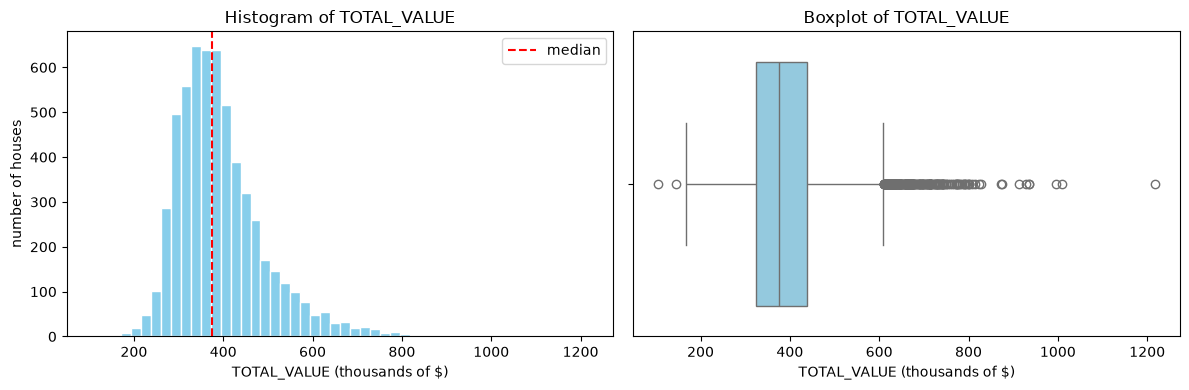

In [56]:
## histogram and boxplot of TOTAL_VALUE, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

## left: histogram = number of houses in each value range ("bin")
axes[0].hist(housing_df['TOTAL_VALUE'], bins=50, color='skyblue', edgecolor='white')
axes[0].axvline(housing_df['TOTAL_VALUE'].median(), color='red', linestyle='--', label='median')
axes[0].set_xlabel('TOTAL_VALUE (thousands of $)')
axes[0].set_ylabel('number of houses')
axes[0].set_title('Histogram of TOTAL_VALUE')
axes[0].legend()

## right: boxplot = median, quartiles, and points far from the box ("outliers")
sns.boxplot(x=housing_df['TOTAL_VALUE'], color='skyblue', ax=axes[1])
axes[1].set_xlabel('TOTAL_VALUE (thousands of $)')
axes[1].set_title('Boxplot of TOTAL_VALUE')

plt.tight_layout()
plt.show()

**How to read the figures:**
- *Histogram:* most houses are valued roughly between 250 and 550 thousand dollars, with a single peak close to the median (red dashed line). On the right there is a long, thin tail of expensive houses, and two houses are above 1,000.
- *Boxplot:* the box covers the middle 50% of houses (from the 25th percentile, about 325, to the 75th percentile, about 439); the line inside the box is the median. The dots are houses far from the box (more than 1.5 times the box width beyond its edges). There are many such dots on the right and only a couple on the left.

**Link with the regression:** the houses that the model under-predicted are in this right tail. There are few of them, so the fitted line is shaped mostly by the many mid-priced houses. This is a *plausible* explanation of the pattern we saw, not a proof.\
*Watch out:* the look of a histogram depends on the number of bins; try `bins=20` or `bins=100`.

### A2. Do larger homes have higher values?

**Question:** is there a relationship between the size of a house (LIVING_AREA, in square feet) and its value?

Our *hypothesis* is an increasing relationship: more living space, higher value. A **scatter plot** (one dot per house) lets us check it.

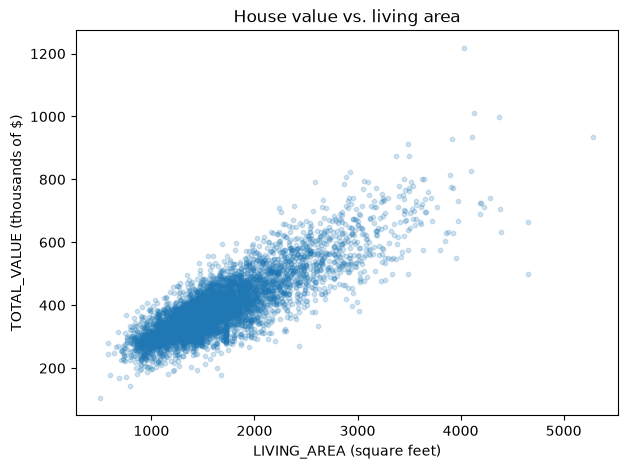

correlation LIVING_AREA vs TOTAL_VALUE: 0.84


In [57]:
## scatter plot: one dot per house
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(housing_df['LIVING_AREA'], housing_df['TOTAL_VALUE'],
           alpha=0.2, s=10)  # alpha < 1: transparent dots, so crowded areas look darker
ax.set_xlabel('LIVING_AREA (square feet)')
ax.set_ylabel('TOTAL_VALUE (thousands of $)')
ax.set_title('House value vs. living area')
plt.show()

## correlation: a number between -1 and 1 summarizing the LINEAR association
print('correlation LIVING_AREA vs TOTAL_VALUE:',
      round(housing_df['LIVING_AREA'].corr(housing_df['TOTAL_VALUE']), 2))

**What do we see?**
- A clear **positive** and roughly **linear** pattern: houses with more living area tend to have higher assessed values. The correlation (about 0.84) is high.
- The vertical spread of the dots gets **wider** for larger houses: two large houses of similar size can have quite different values. Predicting the value of large houses is therefore harder, which is consistent with the regression results above.

**Association is not causation.** Larger houses also tend to have larger lots, more bathrooms, and may be located in different streets. The plot tells us that size and value *move together* in this sample; it does not tell us by how much the value of a given house would change if we added 100 square feet.

### A3. Which characteristics move together?

Looking at one scatter plot at a time quickly becomes tedious. A **correlation heatmap** summarizes all the pairwise correlations of a small set of variables in one picture.

Before drawing it, a word about **TAX**. Chapter 2 excluded TAX from the predictors (`excludetarget`). The next cell shows why.

In [58]:
## TAX vs TOTAL_VALUE: correlation and ratio
print('correlation TAX vs TOTAL_VALUE:', round(housing_df['TAX'].corr(housing_df['TOTAL_VALUE']), 4))

tax_ratio = housing_df['TAX'] / housing_df['TOTAL_VALUE']  # TAX (in $) per thousand $ of value
print(tax_ratio.describe().round(2))

correlation TAX vs TOTAL_VALUE: 1.0
count    5802.00
mean       12.58
std         0.00
min        12.57
25%        12.58
50%        12.58
75%        12.58
max        12.58
dtype: float64


The ratio TAX / TOTAL_VALUE is practically the **same number (about 12.58) for every house**, and the correlation is essentially 1.\
In other words, the tax bill is computed from the assessed value (roughly 1.26% of it): TAX already "contains the answer". Using it to explain or to summarize house values would be circular, so we leave it out of everything that follows.

Now the heatmap, on a small set of interpretable variables.

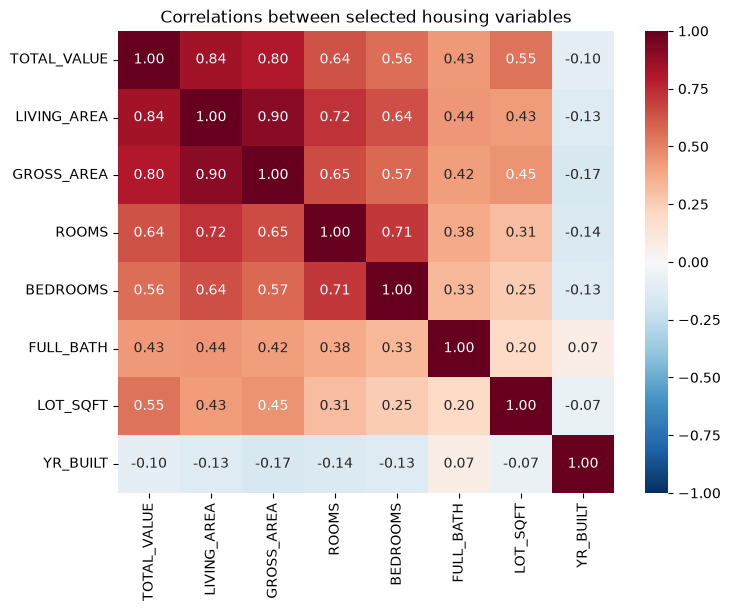

In [59]:
## a small set of interpretable variables (TAX excluded on purpose)
heatmap_vars = ['TOTAL_VALUE', 'LIVING_AREA', 'GROSS_AREA', 'ROOMS',
                'BEDROOMS', 'FULL_BATH', 'LOT_SQFT', 'YR_BUILT']
corr_matrix = housing_df[heatmap_vars].corr()  # table of pairwise correlations

## heatmap: red = positive, blue = negative, white = close to zero
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f',  # annot=True writes the numbers in the cells
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Correlations between selected housing variables')
plt.show()

**How to read the heatmap:** each cell is the correlation between the row variable and the column variable; the diagonal is always 1.

- **TOTAL_VALUE** is most strongly correlated with LIVING_AREA (0.84) and GROSS_AREA (0.80), then ROOMS (0.64), BEDROOMS and LOT_SQFT (both about 0.55).
- The **size variables are strongly correlated with each other**: LIVING_AREA and GROSS_AREA (0.90), LIVING_AREA and ROOMS (0.72), ROOMS and BEDROOMS (0.71). They largely tell the *same story*: "this is a big house".
- **YR_BUILT** is only weakly correlated with everything else (all correlations between −0.17 and 0.07).

*Watch out:* a correlation measures only **linear** association between **two** variables at a time. It says nothing about cause and effect, and a correlation close to zero does not exclude a non-linear relationship.

**Next idea.** Several columns carry overlapping information about house size. Can we summarize them with fewer, new variables? This is the idea behind **Principal Component Analysis**.

---
# Part B — From correlations to Principal Component Analysis (PCA)

The heatmap showed that LIVING_AREA, GROSS_AREA, ROOMS and BEDROOMS move closely together. Overlapping information is common in real data, and it has practical costs: for example, in the first regression we run the coefficient of BEDROOMS was small and not statistically significant once LIVING_AREA, ROOMS and the other variables were included. Part of the reason is that BEDROOMS adds little information beyond the other size variables.

**What is a principal component (PC)?**
- A PC is a **new variable** built as a **weighted sum** of the original (standardized) variables. The weights are called **loadings**.
- **PC1** uses the weights that make the new variable **spread out as much as possible** across houses, i.e., it captures the largest possible share of the total variation in the data.
- **PC2** does the same with what is left, under the condition of being **uncorrelated** with PC1; and so on for PC3, PC4, ...
- With 7 original variables we get 7 PCs. All 7 together contain all the information; the hope is that the **first few** capture most of it.

**PCA is unsupervised:** it only looks at the property characteristics. It never sees TOTAL_VALUE. We will use house values only *afterwards*, to interpret the results.

In [60]:
## new tool for this part
from sklearn.decomposition import PCA

### B1. Choosing the features and checking the data

We select **7 numeric characteristics** of the houses:

| feature | meaning |
|---|---|
| LOT_SQFT | lot size (square feet) |
| LIVING_AREA | living area (square feet) |
| GROSS_AREA | gross floor area (square feet) |
| ROOMS | number of rooms |
| BEDROOMS | number of bedrooms |
| FULL_BATH | number of full bathrooms |
| YR_BUILT | year of construction |

What we leave out, and why:
- **TOTAL_VALUE**: the variable we want to *interpret* afterwards; including it would mix the answer into the summary.
- **TAX**: practically a copy of TOTAL_VALUE (see Part A).
- **REMODEL**: categorical and missing for most houses; it would need extra treatment.
- **FLOORS, HALF_BATH, FIREPLACE, KITCHEN**: take only a few distinct values (KITCHEN is 1 for about 98% of houses, and FLOORS contains a suspicious value of 15). We leave them out to keep the example small and readable.

We build a **fresh** DataFrame with `.copy()`, so that `housing_df` is not affected by anything we do next.

In [61]:
## the features used for PCA (and later for K-means)
pca_features = ['LOT_SQFT', 'LIVING_AREA', 'GROSS_AREA', 'ROOMS',
                'BEDROOMS', 'FULL_BATH', 'YR_BUILT']

features_df = housing_df[pca_features].copy()  # a separate copy: housing_df stays untouched
print('shape:', features_df.shape)

## count the missing values (NaN) in each column
features_df.isna().sum()

shape: (5802, 7)


LOT_SQFT       0
LIVING_AREA    0
GROSS_AREA     0
ROOMS          0
BEDROOMS       0
FULL_BATH      0
YR_BUILT       0
dtype: int64

No missing values (NaN) in these columns. But missing information can also hide behind **implausible values**. Let us look at the minimum and maximum of each column.

In [62]:
## descriptive statistics in original units
features_df.describe().round(1)

,LOT_SQFT,LIVING_AREA,GROSS_AREA,ROOMS,BEDROOMS,FULL_BATH,YR_BUILT
count,5802.0,5802.0,5802.0,5802.0,5802.0,5802.0,5802.0
mean,6278.1,1657.1,2924.8,7.0,3.2,1.3,1936.7
std,2669.7,540.5,884.0,1.4,0.8,0.5,36.0
min,997.0,504.0,821.0,3.0,1.0,1.0,0.0
25%,4772.0,1308.0,2347.0,6.0,3.0,1.0,1920.0
50%,5683.0,1548.5,2700.0,7.0,3.0,1.0,1935.0
75%,7022.2,1873.8,3239.0,8.0,4.0,2.0,1955.0
max,46411.0,5289.0,8154.0,14.0,9.0,5.0,2011.0


Look at the `min` row: **YR_BUILT has a minimum of 0**. No house in West Roxbury was built in year 0: this is a data-entry error (an unknown year coded as 0).\
How many houses are affected, and how extreme is this value once standardized?

In [63]:
## how many houses have YR_BUILT equal to 0?
print('houses with YR_BUILT == 0:', (features_df['YR_BUILT'] == 0).sum())

## z-score of year 0: (value - mean) / std
yr_mean = features_df['YR_BUILT'].mean()
yr_std = features_df['YR_BUILT'].std()
print('z-score of year 0:', round((0 - yr_mean) / yr_std, 1))

houses with YR_BUILT == 0: 1
z-score of year 0: -53.8


A single house, but its standardized value is about **54 standard deviations below the mean**. Such a value would distort both the standardization and the PCA.

We treat it as a **missing value**. Since only one house out of 5,802 is affected, the simplest transparent choice is to **drop that row from this analysis** (an alternative, as in Chapter 2, would be to impute the median year). `housing_df` itself is not changed.

In [64]:
## keep only the houses with a plausible construction year
plausible_year = features_df['YR_BUILT'] > 0  # True/False for each house
features_df = features_df[plausible_year]

print('houses kept:', features_df.shape[0], 'out of', housing_df.shape[0])
print('missing values left:', features_df.isna().sum().sum())

houses kept: 5801 out of 5802
missing values left: 0


*Side remark:* this house was also included in the heatmap of Part A. With 5,802 houses, one row changes the YR_BUILT correlations only slightly, but it is a good reminder to **always look at min and max values** before an analysis.

### B2. Why scaling matters

PCA looks for directions in which the data **vary the most**. The variables, however, are measured in very different units: lot size varies by thousands of square feet, the number of bedrooms by less than one. Let us check the standard deviations.

In [65]:
## standard deviations in original units
features_df.std().round(2)

LOT_SQFT       2669.92
LIVING_AREA     540.35
GROSS_AREA      883.74
ROOMS             1.44
BEDROOMS          0.85
FULL_BATH         0.52
YR_BUILT         25.47
dtype: float64

LOT_SQFT has a standard deviation in the thousands, BEDROOMS and FULL_BATH below one.\
What happens if we run PCA on these **unscaled** numbers? We do it once, only to see the problem.

In [66]:
## PCA on UNSCALED data: for illustration only, we will not use this result
pca_unscaled = PCA(n_components=1)
pca_unscaled.fit(features_df)

print('share of variation captured by PC1:', round(pca_unscaled.explained_variance_ratio_[0], 3))
print('loadings (weights) of PC1 without scaling:')
print(pd.Series(pca_unscaled.components_[0], index=pca_features).round(3))

share of variation captured by PC1: 0.898
loadings (weights) of PC1 without scaling:
LOT_SQFT       0.982
LIVING_AREA    0.095
GROSS_AREA     0.164
ROOMS          0.000
BEDROOMS       0.000
FULL_BATH      0.000
YR_BUILT      -0.001
dtype: float64


Without scaling, PC1 puts almost all its weight on **LOT_SQFT** (a weight close to 1 in absolute value) and almost none on rooms, bedrooms or bathrooms. PC1 would simply be "lot size", only because lot size has the **largest numbers**, not because it is the most informative variable.

The fix is the **standardization** we already met in Chapter 2: each column becomes a **z-score**, $z = (x - \text{mean}) / \text{std}$, with mean 0 and standard deviation 1. All features then count on the same footing.\
We create a **new** scaler (`feature_scaler`), so that Chapter 2's `scaler` is left untouched.

In [67]:
## standardize the 7 features: z-scores with mean 0 and std 1
feature_scaler = StandardScaler()
features_z = feature_scaler.fit_transform(features_df)  # a numpy array (numbers only)

## put the z-scores back into a DataFrame, with the same row labels and column names
features_z_df = pd.DataFrame(features_z, index=features_df.index, columns=pca_features)
features_z_df.describe().round(2)

,LOT_SQFT,LIVING_AREA,GROSS_AREA,ROOMS,BEDROOMS,FULL_BATH,YR_BUILT
count,5801.00,5801.00,5801.00,5801.00,5801.00,5801.00,5801.00
mean,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.98,-2.13,-2.38,-2.78,-2.63,-0.57,-5.46
25%,-0.56,-0.65,-0.65,-0.69,-0.27,-0.57,-0.67
50%,-0.22,-0.20,-0.25,0.00,-0.27,-0.57,-0.08
75%,0.28,0.40,0.36,0.70,0.91,1.35,0.70
max,15.03,6.72,5.92,4.87,6.82,7.10,2.90


Every column now has mean 0 and standard deviation 1.

**From z-scores back to original units.** The scaler remembers the mean and the standard deviation of each feature:

In [68]:
## means and standard deviations used by the scaler (original units)
scaling_table = pd.DataFrame({'mean': feature_scaler.mean_,
                              'std': feature_scaler.scale_},
                             index=pca_features)
scaling_table.round(1)

,mean,std
LOT_SQFT,6278.0,2669.7
LIVING_AREA,1656.9,540.3
GROSS_AREA,2924.5,883.7
ROOMS,7.0,1.4
BEDROOMS,3.2,0.8
FULL_BATH,1.3,0.5
YR_BUILT,1937.1,25.5


So, for example, a house with a LIVING_AREA z-score of **+1** has about 540 square feet more than the average house (about 1,657 sq ft), i.e., roughly 2,200 sq ft. In general: *original value = mean + z × std*.

### B3. Fitting PCA and measuring explained variance

In [69]:
## fit PCA on the STANDARDIZED features (TOTAL_VALUE and TAX are not included)
pca_model = PCA()  # keep all 7 components for now
pc_scores = pca_model.fit_transform(features_z)  # the new variables: one row per house, one column per PC

## names PC1, PC2, ..., PC7 and a DataFrame of scores
pc_names = ['PC' + str(i + 1) for i in range(pca_model.n_components_)]
pc_scores_df = pd.DataFrame(pc_scores, index=features_df.index, columns=pc_names)
pc_scores_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-0.454623,-2.151574,1.372058,0.915063,-0.879525,-0.277075,0.155906
1,2.071369,0.842976,-0.854545,0.023043,-0.844449,1.033688,0.047030
2,0.288125,-1.936247,-0.203277,0.053257,-1.467097,0.155093,0.054859
3,3.977509,0.081637,1.772379,-2.099026,-0.001670,-0.545879,-0.498525
4,-0.214710,-0.122577,-0.614635,1.688605,-0.655572,0.234115,0.179778


Each row is still a house, but the columns are now the **principal component scores**: the value of each new variable for that house.\
How much of the total variation does each PC capture?

In [70]:
## proportion of the total variation captured by each PC, and the running total
variance_table = pd.DataFrame({
    'proportion of variance': pca_model.explained_variance_ratio_,
    'cumulative proportion': np.cumsum(pca_model.explained_variance_ratio_)  # running sum
}, index=pc_names)
variance_table.round(3)

,proportion of variance,cumulative proportion
PC1,0.518,0.518
PC2,0.158,0.676
PC3,0.119,0.795
PC4,0.087,0.882
PC5,0.066,0.948
PC6,0.039,0.987
PC7,0.013,1.000


**Reading the table:**
- **PC1 alone captures about 52%** of the total variation of the 7 standardized features.
- PC2 adds about 16%, so **PC1 and PC2 together capture about 68%**. This is a useful summary, but about one third of the variation is **not** in the first two components.
- PC3 adds about 12% (cumulative about 80%).

So two PCs do **not** automatically retain "enough" information: how much is enough depends on the purpose. A **scree plot** shows the same numbers graphically.

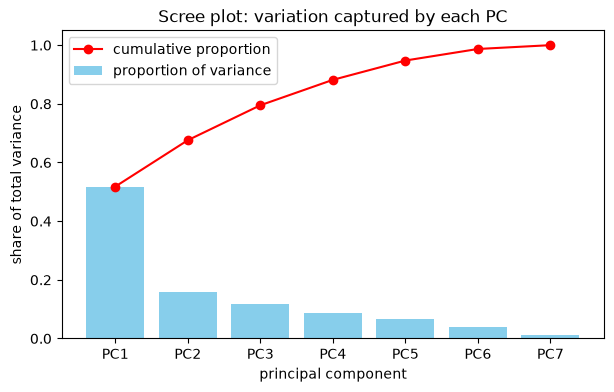

In [71]:
## scree plot (bars) with the cumulative proportion (line)
component_numbers = np.arange(1, len(pc_names) + 1)  # 1, 2, ..., 7

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(component_numbers, pca_model.explained_variance_ratio_,
       color='skyblue', label='proportion of variance')
ax.plot(component_numbers, np.cumsum(pca_model.explained_variance_ratio_),
        'ro-', label='cumulative proportion')
ax.set_xticks(component_numbers)
ax.set_xticklabels(pc_names)
ax.set_ylim(0, 1.05)
ax.set_xlabel('principal component')
ax.set_ylabel('share of total variance')
ax.set_title('Scree plot: variation captured by each PC')
ax.legend()
plt.show()

The bars drop sharply after PC1 and then decline slowly. A common rule of thumb looks for the **elbow**, where the bars level off; here the clearest break is after PC1. If we want to keep, say, 80% of the variation, we need three components. There is no single correct number: it is a judgement call.

### B4. What do the components mean? Loadings

To interpret a PC, we look at its **loadings**: the weight given to each standardized feature. We show the first three PCs.

In [72]:
## loadings: rows = original features, columns = PCs
loadings_df = pd.DataFrame(pca_model.components_[:3].T,  # .T turns rows into columns
                           index=pca_features,
                           columns=pc_names[:3])
loadings_df.round(2)

,PC1,PC2,PC3
LOT_SQFT,0.28,-0.02,0.89
LIVING_AREA,0.48,0.02,0.01
GROSS_AREA,0.47,-0.03,0.09
ROOMS,0.44,-0.05,-0.25
BEDROOMS,0.41,-0.05,-0.35
FULL_BATH,0.29,0.54,-0.12
YR_BUILT,-0.12,0.83,0.06


**Reading the loadings** (focus on the large weights, in absolute value):
- **PC1**: LIVING_AREA, GROSS_AREA, ROOMS and BEDROOMS all get large weights of the **same sign** (about 0.41–0.48 in absolute value); LOT_SQFT and FULL_BATH get smaller weights of the same sign; YR_BUILT gets a small weight of the opposite sign. PC1 is an **overall "size" index** of the house.
- **PC2**: dominated by **YR_BUILT** and **FULL_BATH**, with near-zero weights on the size variables. It separates newer houses with more full bathrooms from older ones, **almost independently of size**.
- **PC3**: dominated by **LOT_SQFT** (with smaller weights of the opposite sign on BEDROOMS and ROOMS). Lot size carries information that PC1 and PC2 do not capture well.

**Watch out: the sign of a PC has no meaning by itself.** Multiplying all loadings of a component by −1 describes exactly the same component (the data are just projected on the opposite direction). Depending on the software version, PC1 may come out with all positive or all negative size loadings. So "a high PC1 score" means "a large house" **only if** the size loadings are positive; always check the loadings before interpreting a score.

### B5. Looking at the houses on the PC1–PC2 map

Each house can now be drawn as one point with coordinates (PC1, PC2). To help interpretation, we **colour** the points by their TOTAL_VALUE. The values are used **only for colouring, after** PCA has been fitted.

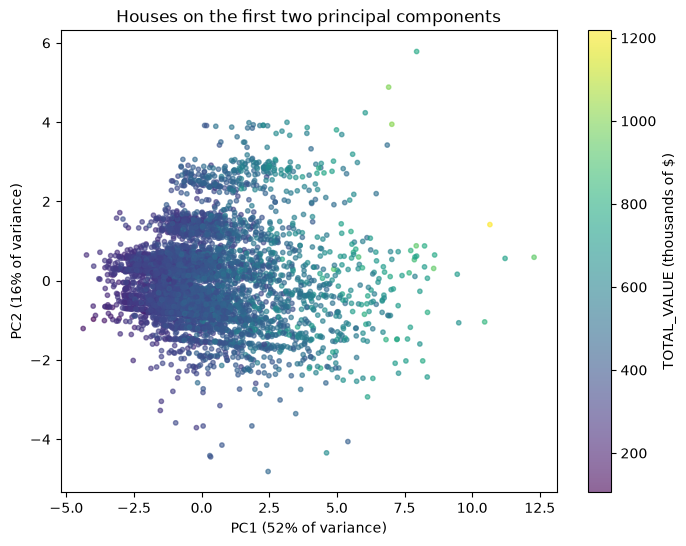

In [73]:
## TOTAL_VALUE of the same houses (used only for colouring, NOT for fitting)
pca_house_values = housing_df.loc[features_df.index, 'TOTAL_VALUE']

fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(pc_scores_df['PC1'], pc_scores_df['PC2'],
                    c=pca_house_values, cmap='viridis', s=10, alpha=0.6)  # c = colour by value
fig.colorbar(points, label='TOTAL_VALUE (thousands of $)')
ax.set_xlabel('PC1 (' + str(round(100 * pca_model.explained_variance_ratio_[0])) + '% of variance)')
ax.set_ylabel('PC2 (' + str(round(100 * pca_model.explained_variance_ratio_[1])) + '% of variance)')
ax.set_title('Houses on the first two principal components')
plt.show()

In [74]:
## after the fact: how strongly is each PC associated with house value?
print('correlation PC1 vs TOTAL_VALUE:', round(pc_scores_df['PC1'].corr(pca_house_values), 2))
print('correlation PC2 vs TOTAL_VALUE:', round(pc_scores_df['PC2'].corr(pca_house_values), 2))

correlation PC1 vs TOTAL_VALUE: 0.83
correlation PC2 vs TOTAL_VALUE: 0.06


**What do we see?**
- The colours change mainly **along the PC1 axis**: higher-value houses sit at the "large size" end of PC1. The correlation between PC1 and TOTAL_VALUE is about **0.83 in absolute value** (its sign simply follows the sign of PC1).
- Along PC2 there is no clear colour pattern, and the correlation with TOTAL_VALUE is close to zero.

**Cautions:**
- PCA was fitted **without** TOTAL_VALUE. Colouring the points by value afterwards does **not** make PCA supervised: PCA did not try to explain values, and it happens that its main axis of variation (size) is related to value.
- PCA does **not** preserve or predict house values. A component with a large share of variance is not necessarily useful for prices, and a small component could still matter.
- We fitted the scaler and PCA on **all** houses: this is a **descriptive** exercise. If we wanted to use PCs as predictors and evaluate predictions honestly, we would fit the scaler and PCA on the **training** data only (as with `train_X` in Chapter 2) and then apply them to the validation data.

---
# Part C — K-means: grouping similar houses

PCA created new **columns** (continuous axes that summarize the features). **Clustering** works on the **rows**: it puts houses that are *similar* into the same group.

**K-means in plain words:**
1. Choose the number of groups, **k**.
2. Place k "average houses", the **centroids**, in the data (initially at random).
3. Assign every house to its **nearest** centroid: this is its cluster **membership**.
4. Move each centroid to the average of the houses assigned to it.
5. Repeat steps 3–4 until nothing changes.

**Why scaling matters here too:** "nearest" is measured by a distance. On the original units, a difference of 1,000 sq ft of lot would swamp a difference of 2 bedrooms. So we reuse the **same standardized features** `features_z` as for PCA. TOTAL_VALUE (the target) is **not** used.

Because step 2 is random, we fix `random_state` for reproducibility, and `n_init=10` runs the algorithm from 10 different starting points and keeps the best result.

In [75]:
## new tool for this part
from sklearn.cluster import KMeans

## K-means with k = 3 groups, on the SAME standardized features used for PCA
kmeans_model = KMeans(n_clusters=3, n_init=10, random_state=1)
cluster_labels = kmeans_model.fit_predict(features_z)  # one label (0, 1 or 2) per house

## store the labels in a pandas Series, aligned with the houses of features_df
cluster_series = pd.Series(cluster_labels, index=features_df.index, name='cluster')

## cluster sizes: how many houses in each group?
cluster_series.value_counts().sort_index()

cluster
0    2087
1    3157
2     557
Name: count, dtype: int64

The three groups have quite different sizes: one large group (a bit more than half of the houses), one medium group, and one small group of fewer than 600 houses.

**The numbers 0, 1, 2 are just labels.** They are assigned arbitrarily by the algorithm: cluster 2 is not "better" or "bigger" than cluster 0, and with another software version or `random_state` the same groups could receive different numbers. To understand the groups we look at their **centroids**.

In [76]:
## cluster centres (centroids) in z-scores: the "average house" of each cluster
centers_z_df = pd.DataFrame(kmeans_model.cluster_centers_, columns=pca_features)
centers_z_df.index.name = 'cluster'
centers_z_df.round(2)

,LOT_SQFT,LIVING_AREA,GROSS_AREA,ROOMS,BEDROOMS,FULL_BATH,YR_BUILT
cluster,,,,,,,
0,0.08,0.34,0.27,0.43,0.38,0.35,0.06
1,-0.28,-0.60,-0.56,-0.60,-0.55,-0.43,0.10
2,1.29,2.13,2.18,1.78,1.67,1.10,-0.76


These are **z-scores**: 0 means "like the average house", +1 means "one standard deviation above the average", −0.5 means "half a standard deviation below".\
Z-scores are good for comparing features with each other, but hard to picture. The same profiles in **original units** are simply the averages of `features_df` within each cluster:

In [77]:
## cluster profiles in ORIGINAL units: average of each feature within each cluster
cluster_profile = features_df.groupby(cluster_series).mean()
cluster_profile.round(1)

,LOT_SQFT,LIVING_AREA,GROSS_AREA,ROOMS,BEDROOMS,FULL_BATH,YR_BUILT
cluster,,,,,,,
0,6502.5,1841.6,3161.2,7.6,3.6,1.5,1938.5
1,5523.3,1331.3,2427.6,6.1,2.8,1.1,1939.5
2,9713.8,2810.3,4854.4,9.5,4.6,1.9,1917.8


**Describing the clusters** (find the matching label number in your own output):
- a **small group of large houses**: all size features well above average (living area around 2,800 sq ft, about 9.5 rooms, larger lots), and on average **older** (built around 1918);
- a **large group of smaller-than-average houses** (living area around 1,330 sq ft, about 6 rooms);
- a **middle group** of moderately above-average houses (living area around 1,840 sq ft, about 7.6 rooms).

The two smaller groups have a similar average construction year (around 1938–1940): K-means separated the houses **mainly by size**.

### Relating clusters to house values (after fitting)

Only now do we bring in TOTAL_VALUE, as an **external** check of what the groups mean.

In [78]:
## house values by cluster: TOTAL_VALUE was NOT used to form the clusters
cluster_values = housing_df.loc[features_df.index, 'TOTAL_VALUE'].groupby(cluster_series).agg(
    ['count', 'mean', 'median', 'min', 'max'])
cluster_values.round(1)

,count,mean,median,min,max
cluster,,,,,
0,2087,423.8,417.2,201.0,715.0
1,3157,339.0,337.5,105.0,557.7
2,557,579.9,562.8,269.0,1217.8


The group of large houses has the highest average value (about 580 thousand dollars), the group of smaller houses the lowest (about 339), and the middle group is in between (about 424).\
This is not surprising, because size and value are strongly correlated (Part A). Note however that the **ranges overlap**: some houses in the "smaller" group are worth more than some houses in the "large" group. The clusters describe *similar characteristics*, not price bands, and they are not a ranking of quality.

### How many clusters? The elbow plot

We chose k = 3 to obtain a small, readable summary. A common heuristic is to compute, for several values of k, the **inertia**: the sum of squared distances between each house and its centroid (smaller = houses closer to their centroid).

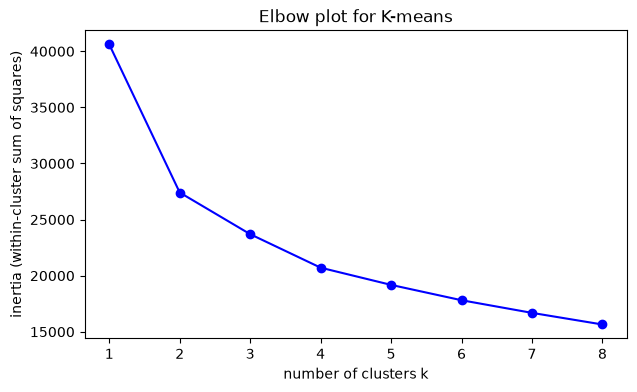

In [79]:
## inertia for k = 1, 2, ..., 8
k_values = range(1, 9)
inertia_values = []  # empty list, filled in the loop
for k in k_values:
    kmeans_k = KMeans(n_clusters=k, n_init=10, random_state=1)
    kmeans_k.fit(features_z)
    inertia_values.append(kmeans_k.inertia_)

## elbow plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(k_values), inertia_values, 'bo-')
ax.set_xlabel('number of clusters k')
ax.set_ylabel('inertia (within-cluster sum of squares)')
ax.set_title('Elbow plot for K-means')
plt.show()

The inertia **always decreases** as k grows (with one cluster per house it would be zero), so we cannot simply pick the smallest value. We look for the point where adding a cluster stops helping much.\
Here the largest drop is from k = 1 to k = 2, a smaller drop follows from 2 to 3, and after that the curve declines gradually, **without a sharp elbow**. k = 3 is therefore a **pragmatic** choice, not the uniquely correct one; k = 2 or k = 4 would also be defensible. The elbow plot is a **heuristic**.

### Clusters on the PCA map

Finally, we combine the two tools: we draw the houses on the PC1–PC2 map of Part B and colour them by **cluster**.

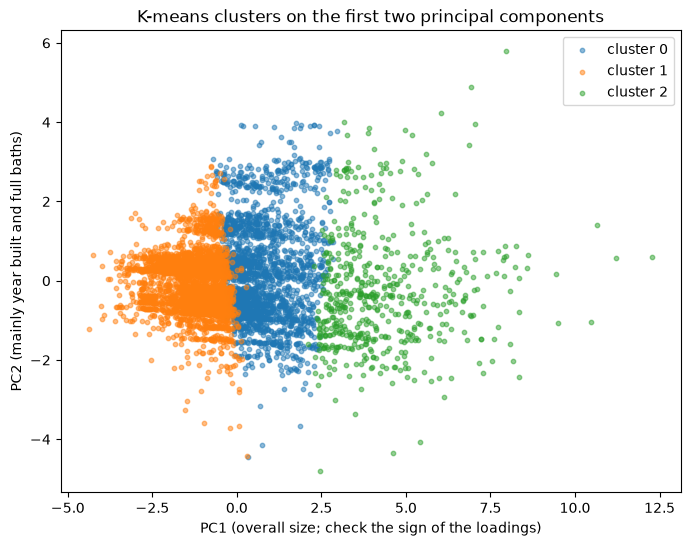

In [80]:
## houses on the PC1-PC2 map, coloured by cluster label
fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in sorted(cluster_series.unique()):
    in_cluster = cluster_series == cluster_id  # True for the houses in this cluster
    ax.scatter(pc_scores_df.loc[in_cluster, 'PC1'], pc_scores_df.loc[in_cluster, 'PC2'],
               s=10, alpha=0.5, label='cluster ' + str(cluster_id))
ax.set_xlabel('PC1 (overall size; check the sign of the loadings)')
ax.set_ylabel('PC2 (mainly year built and full baths)')
ax.set_title('K-means clusters on the first two principal components')
ax.legend()
plt.show()

**What do we see?**
- The clusters are separated mainly **along PC1**, the size axis: this matches the centroids, which differ mostly in the size features.
- The houses do not form three well-separated "islands": they form one continuous cloud, and K-means **cuts** it into slices, roughly from smaller to larger houses. Clusters are a convenient summary, not natural categories discovered in the data.
- Near the boundaries a few points of different colours mix. The map shows only 2 of the 7 dimensions (about 68% of the variation), so houses that look close here can be farther apart in the dimensions we do not see.

---
# Part D — Putting it all together

We used one dataset, West Roxbury, and four tools that answer **different questions**:

| tool | question it answers | uses TOTAL_VALUE? |
|---|---|---|
| **Linear regression** (Chapter 2) | How well can we *predict* (or explain) TOTAL_VALUE from the other variables? | yes: it is the target |
| **Visualization** (Part A) | What is the *shape* of the data, and which variables move together? | yes, as one of the variables we look at |
| **PCA** (Part B) | Can we *compress* several correlated characteristics into a few new continuous variables? | no (only afterwards, to interpret) |
| **K-means** (Part C) | Can we *group* houses with similar characteristics? | no (only afterwards, to interpret) |

**What we learned about West Roxbury houses (in this sample):**
- values have a long right tail of expensive houses, which the regression tends to under-predict;
- size variables are strongly correlated with each other and with value;
- one "size" component captures about half of the variation of seven characteristics; year built and lot size carry largely separate information;
- K-means groups the houses mainly by size, and the groups differ in average value.